In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 644.1 kB/s eta 0:01:16
    --------------------------------------- 0.8/48.9 MB 699.0 kB/s eta 0:01:09
    --------------------------------------- 0.8/48.9 MB 699.0 kB/s eta 0:01:09
    --------------------------------------- 0.8/48.9 MB 699.0 kB/s eta 0:01:09
    --------------------------------------- 1.0/48.9 MB 621.2 kB/s eta 0:01:18
    --------------------------------------- 1.0/48.9 MB 621.2 kB/s eta 0:01:18
   - -------------------------------------- 1.3/48.9 MB 583.5 kB/s eta 0:01:22
   - -------------------------------------- 1.3/48.9 MB 583.5 kB/s eta 0:01:22
   - -------------------------------------- 1.3/48.9 MB 583.5 kB/s eta 0:01:22
   - ---


[notice] A new release of pip is available: 25.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display the first five rows
print("First five rows:")
display(df.head())

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [4]:
# Statistical summary
print("Statistical summary:")
display(df.describe(include="all").T)

# Check missing values
print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

# Check duplicate records
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Examine the target variable
print("\nChurn distribution:")
display(df["Churn"].value_counts())

# Examine class percentages
print("\nChurn percentages:")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Number of duplicate rows:
0

Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

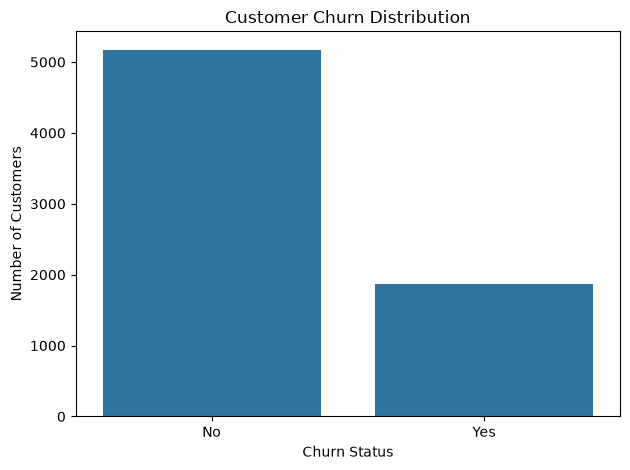

In [5]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

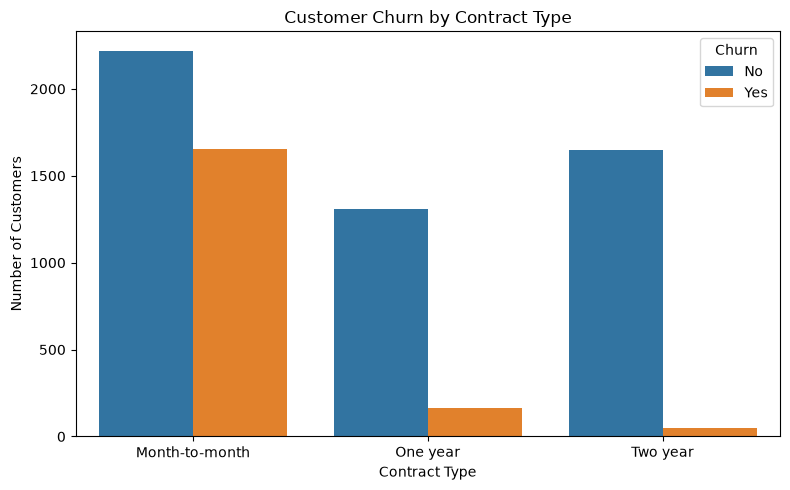

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

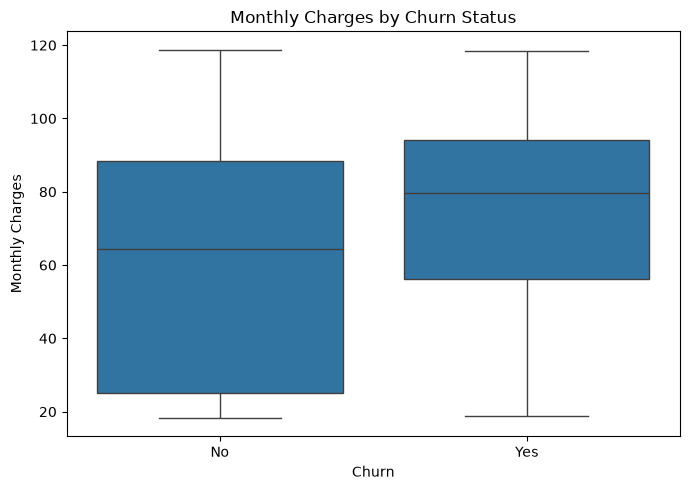

In [7]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

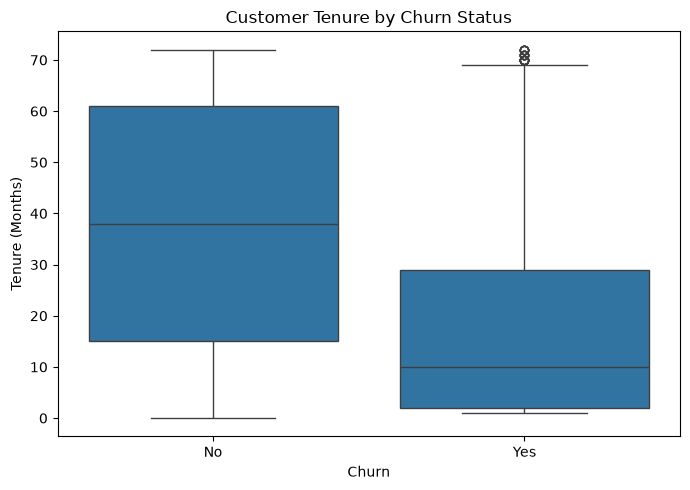

In [8]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

In [9]:
# Create a copy of the original dataset
data = df.copy()

# Convert TotalCharges to numeric
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

# Encode the target variable
data["Churn"] = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Remove the customer ID column
X = data.drop(columns=["Churn", "customerID"])

# Target variable
y = data["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features: (7043, 19)
Target: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5634
Testing records: 1409


In [11]:
# Identify numerical features
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [12]:
# Numerical preprocessing for Logistic Regression
numeric_logistic = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical preprocessing for tree-based models
numeric_trees = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocessing for Logistic Regression
preprocess_logistic = ColumnTransformer([
    ("num", numeric_logistic, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Preprocessing for Decision Tree, Random Forest, and XGBoost
preprocess_trees = ColumnTransformer([
    ("num", numeric_trees, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipelines created successfully!")

Preprocessing pipelines created successfully!


In [14]:
# Define the model
logistic_model = Pipeline([
    ("preprocessing", preprocess_logistic),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train the model
start_time = time.time()

logistic_model.fit(X_train, y_train)

logistic_time = time.time() - start_time

# Make predictions
logistic_predictions = logistic_model.predict(X_test)

# Predict churn probabilities
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully!")
print("Training time:", round(logistic_time, 3), "seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Logistic Regression trained successfully!
Training time: 0.087 seconds

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [15]:
# Define the model
decision_tree_model = Pipeline([
    ("preprocessing", preprocess_trees),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Train the model
start_time = time.time()

decision_tree_model.fit(X_train, y_train)

decision_tree_time = time.time() - start_time

# Make predictions
decision_tree_predictions = decision_tree_model.predict(X_test)

# Predict churn probabilities
decision_tree_probabilities = (
    decision_tree_model.predict_proba(X_test)[:, 1]
)

print("Decision Tree trained successfully!")
print("Training time:", round(decision_tree_time, 3), "seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        decision_tree_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)


Decision Tree trained successfully!
Training time: 0.068 seconds

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.82      0.81      0.81      1035
       Churn       0.49      0.51      0.50       374

    accuracy                           0.73      1409
   macro avg       0.65      0.66      0.66      1409
weighted avg       0.73      0.73      0.73      1409



In [16]:
# Define the model
random_forest_model = Pipeline([
    ("preprocessing", preprocess_trees),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
start_time = time.time()

random_forest_model.fit(X_train, y_train)

random_forest_time = time.time() - start_time

# Make predictions
random_forest_predictions = random_forest_model.predict(X_test)

# Predict churn probabilities
random_forest_probabilities = (
    random_forest_model.predict_proba(X_test)[:, 1]
)

print("Random Forest trained successfully!")
print("Training time:", round(random_forest_time, 3), "seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        random_forest_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

Random Forest trained successfully!
Training time: 0.764 seconds

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.61      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [17]:
# Define the model
xgboost_model = Pipeline([
    ("preprocessing", preprocess_trees),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
start_time = time.time()

xgboost_model.fit(X_train, y_train)

xgboost_time = time.time() - start_time

# Make predictions
xgboost_predictions = xgboost_model.predict(X_test)

# Predict churn probabilities
xgboost_probabilities = xgboost_model.predict_proba(X_test)[:, 1]

print("XGBoost trained successfully!")
print("Training time:", round(xgboost_time, 3), "seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgboost_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

XGBoost trained successfully!
Training time: 0.666 seconds

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



In [18]:
# Store the predictions and probabilities
model_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions,
    "XGBoost": xgboost_predictions
}

model_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Decision Tree": decision_tree_probabilities,
    "Random Forest": random_forest_probabilities,
    "XGBoost": xgboost_probabilities
}

# Calculate evaluation metrics
results = []

for name in model_predictions:

    y_pred = model_predictions[name]
    y_prob = model_probabilities[name]

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("MODEL COMPARISON RESULTS")

display(
    results_df.round(4).sort_values(
        by="F1-score",
        ascending=False
    )
)

MODEL COMPARISON RESULTS


,Algorithm,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
3,XGBoost,0.8027,0.6589,0.5321,0.5888,0.8428
2,Random Forest,0.7807,0.6109,0.4786,0.5367,0.8179
1,Decision Tree,0.7289,0.4896,0.5053,0.4974,0.6573


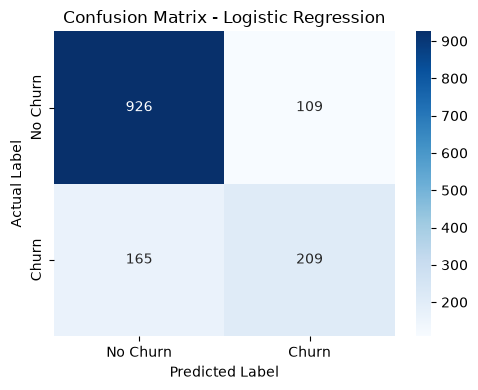

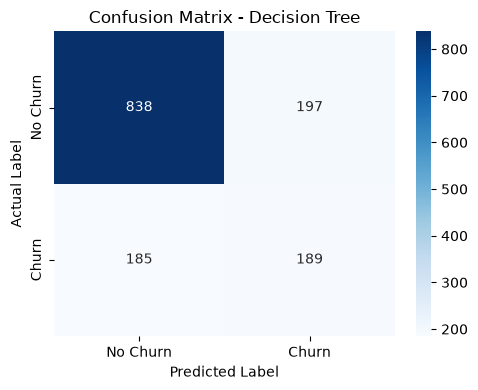

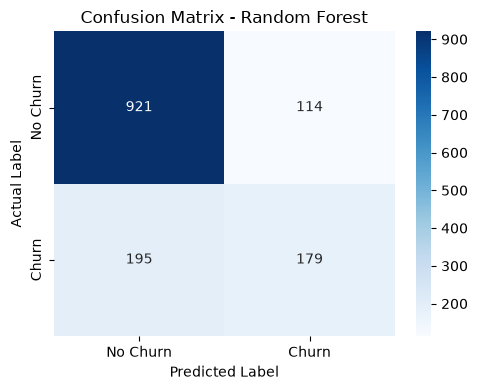

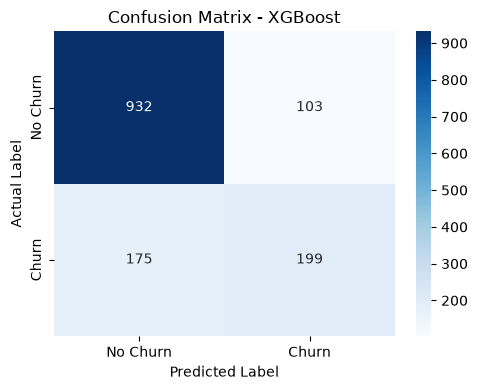

In [19]:
for name, predictions in model_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

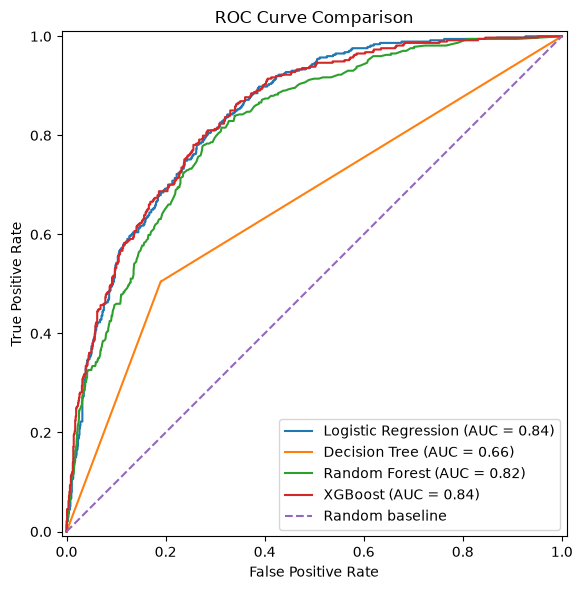

In [20]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(9, 6))

for name, probabilities in model_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.tight_layout()
plt.show()

In [21]:
results_df.to_csv(
    "Telco_Churn_Model_Comparison_Results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [22]:
import joblib

joblib.dump(
    logistic_model,
    "logistic_regression_model.joblib"
)

joblib.dump(
    decision_tree_model,
    "decision_tree_model.joblib"
)

joblib.dump(
    random_forest_model,
    "random_forest_model.joblib"
)

joblib.dump(
    xgboost_model,
    "xgboost_model.joblib"
)

print("All four trained models saved successfully!")

All four trained models saved successfully!
